# 02 — Statistical A/B Experiment Analysis (Frequentist & Bayesian)

End-to-end statistical evaluation of the Checkout Redesign experiment: power adequacy, SRM validity gate, Frequentist hypothesis tests with BH-FDR subgroup control, Bayesian Beta-Binomial inference (95% HDI, ROPE, Expected Loss, prior sensitivity), and final business recommendation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

%matplotlib inline
plt.rcParams['figure.dpi'] = 120


In [2]:
from IPython.display import Image, display as ipy_display
from src.bayesian import run_bayesian_analysis
from src.data_pipeline import load_or_generate_data
from src.frequentist import check_srm, run_frequentist_analysis
from src.power import run_power_analysis
from src.report import build_analysis_report
from src.schemas import ExperimentConfig
from src.visualizations import generate_all_figures

config = ExperimentConfig(seed=42, n_users=40000)
clean_df, quality = load_or_generate_data(config, csv_path=ROOT / 'data' / 'ab_test_data.csv')
ctrl_n = int((clean_df['group'] == 'control').sum())
trt_n = int((clean_df['group'] == 'treatment').sum())
print(f'Clean rows: {len(clean_df):,} (Control={ctrl_n:,}, Treatment={trt_n:,})')

Clean rows: 39,880 (Control=19,850, Treatment=20,030)


## 1. Power Analysis & Sample Size Planning

In [3]:
power_res = run_power_analysis(config, actual_control_n=ctrl_n, actual_treatment_n=trt_n)
power_summary = {
    'baseline_cr': power_res.baseline_cr,
    'target_cr': power_res.target_cr,
    'required_sample_per_variant': power_res.required_sample_per_variant,
    'estimated_duration_days': power_res.estimated_duration_days,
    'actual_sample_per_variant': power_res.actual_sample_per_variant,
    'achieved_power': round(power_res.achieved_power, 4),
}
display(pd.DataFrame([power_summary]))

,baseline_cr,target_cr,required_sample_per_variant,estimated_duration_days,actual_sample_per_variant,achieved_power
0,0.1,0.112,10323,7,19850,0.9734


## 2. Sample Ratio Mismatch (SRM) Gate

In [4]:
srm = check_srm(control_n=ctrl_n, treatment_n=trt_n)
display(pd.DataFrame([srm.model_dump()]))
assert srm.passed, 'SRM gate failed — do not interpret treatment effects!'

,control_n,treatment_n,expected_ratio,chi2_stat,p_value,alpha,passed
0,19850,20030,0.5,0.812437,0.367401,0.001,True


## 3. Frequentist Inference & BH-FDR Subgroup Analysis

In [5]:
freq = run_frequentist_analysis(clean_df, alpha=config.alpha)
freq_overview = pd.DataFrame([
    {
        'control_cr': f'{freq.control_cr:.4%}',
        'treatment_cr': f'{freq.treatment_cr:.4%}',
        'abs_diff_pp': round(freq.abs_diff * 100.0, 3),
        'rel_lift': f'{freq.rel_lift:.2%}',
        'z_p_value': round(freq.z_p_value, 6),
        'chi2_p_value': round(freq.chi2_p_value, 6),
        'cohens_h': round(freq.cohens_h, 4),
        'rpu_diff_usd': round(freq.rpu_diff, 2),
        'rpu_welch_p': round(freq.rpu_welch_p, 6),
        'rpu_mannwhitney_p': round(freq.rpu_mannwhitney_p, 6),
    }
])
display(freq_overview)

seg_df = pd.DataFrame([s.model_dump() for s in freq.segments])
display(seg_df.round(4))

,control_cr,treatment_cr,abs_diff_pp,rel_lift,z_p_value,chi2_p_value,cohens_h,rpu_diff_usd,rpu_welch_p,rpu_mannwhitney_p
0,9.6927%,11.5377%,1.845,19.03%,0.0,0.0,0.0599,1.22,0.0,0.0


,dimension,segment,control_n,control_cr,treatment_n,treatment_cr,abs_diff,rel_lift,ci_low,ci_high,p_value,p_value_bh,significant_bh
0,device,desktop,8926,0.1104,8927,0.1306,0.0203,0.1836,0.0107,0.0298,0.0000,0.0001,True
1,device,mobile,8559,0.0853,8647,0.1066,0.0213,0.2502,0.0125,0.0301,0.0000,0.0000,True
2,device,tablet,2365,0.0884,2456,0.0908,0.0024,0.0275,-0.0138,0.0186,0.7681,0.7681,False
3,channel,email,2996,0.1185,3005,0.1511,0.0326,0.2750,0.0153,0.0499,0.0002,0.0004,True
4,channel,organic,8014,0.0962,7917,0.1148,0.0186,0.1934,0.0091,0.0282,0.0001,0.0003,True
5,channel,paid_search,5941,0.0943,6046,0.1095,0.0152,0.1616,0.0044,0.0261,0.0059,0.0082,True
6,channel,social,2899,0.0821,3062,0.0934,0.0113,0.1377,-0.0031,0.0257,0.1234,0.1439,False


## 4. Bayesian Beta-Binomial Inference & Prior Sensitivity

In [6]:
bayes = run_bayesian_analysis(
    control_n=ctrl_n,
    control_conv=freq.control_conversions,
    treatment_n=trt_n,
    treatment_conv=freq.treatment_conversions,
    config=config,
)
bayes_summary = pd.DataFrame([{
    'prob_treatment_beats_control': round(bayes.prob_treatment_beats_control, 4),
    'expected_loss_treatment': round(bayes.expected_loss_treatment, 6),
    'rel_lift_mean': f'{bayes.rel_lift_mean:.2%}',
    'rel_lift_95_hdi': f'[{bayes.rel_lift_hdi_low:.2%}, {bayes.rel_lift_hdi_high:.2%}]',
    'prob_above_rope': round(bayes.prob_above_rope, 4),
    'prob_in_rope': round(bayes.prob_in_rope, 4),
}])
display(bayes_summary)
display(pd.DataFrame([s.model_dump() for s in bayes.sensitivity]).round(5))

,prob_treatment_beats_control,expected_loss_treatment,rel_lift_mean,rel_lift_95_hdi,prob_above_rope,prob_in_rope
0,1.0,0.0,18.97%,"[12.20%, 25.78%]",1.0,0.0


,prior_name,prior_alpha,prior_beta,prob_treatment_beats_control,expected_loss_treatment,rel_lift_mean,hdi_low,hdi_high
0,"Weak Uniform Beta(1, 1)",1.0,1.0,1.0,0.0,0.19061,0.12272,0.25890
1,"Informative Beta(10, 90)",10.0,90.0,1.0,0.0,0.18973,0.12203,0.25782
2,"Skeptical Beta(20, 180)",20.0,180.0,1.0,0.0,0.18876,0.12127,0.25663


## 5. Report Figures & Final Decision

Decision: SHIP
Ship the checkout redesign: conversion rate rose from 9.69% to 11.54% (+19.03% relative lift, p = < 0.0001), backed by 100.00% Bayesian probability of beating control, 100.00% probability above the practical significance threshold (ROPE), and +$1.22 incremental revenue per user.
--- conversion_funnel ---


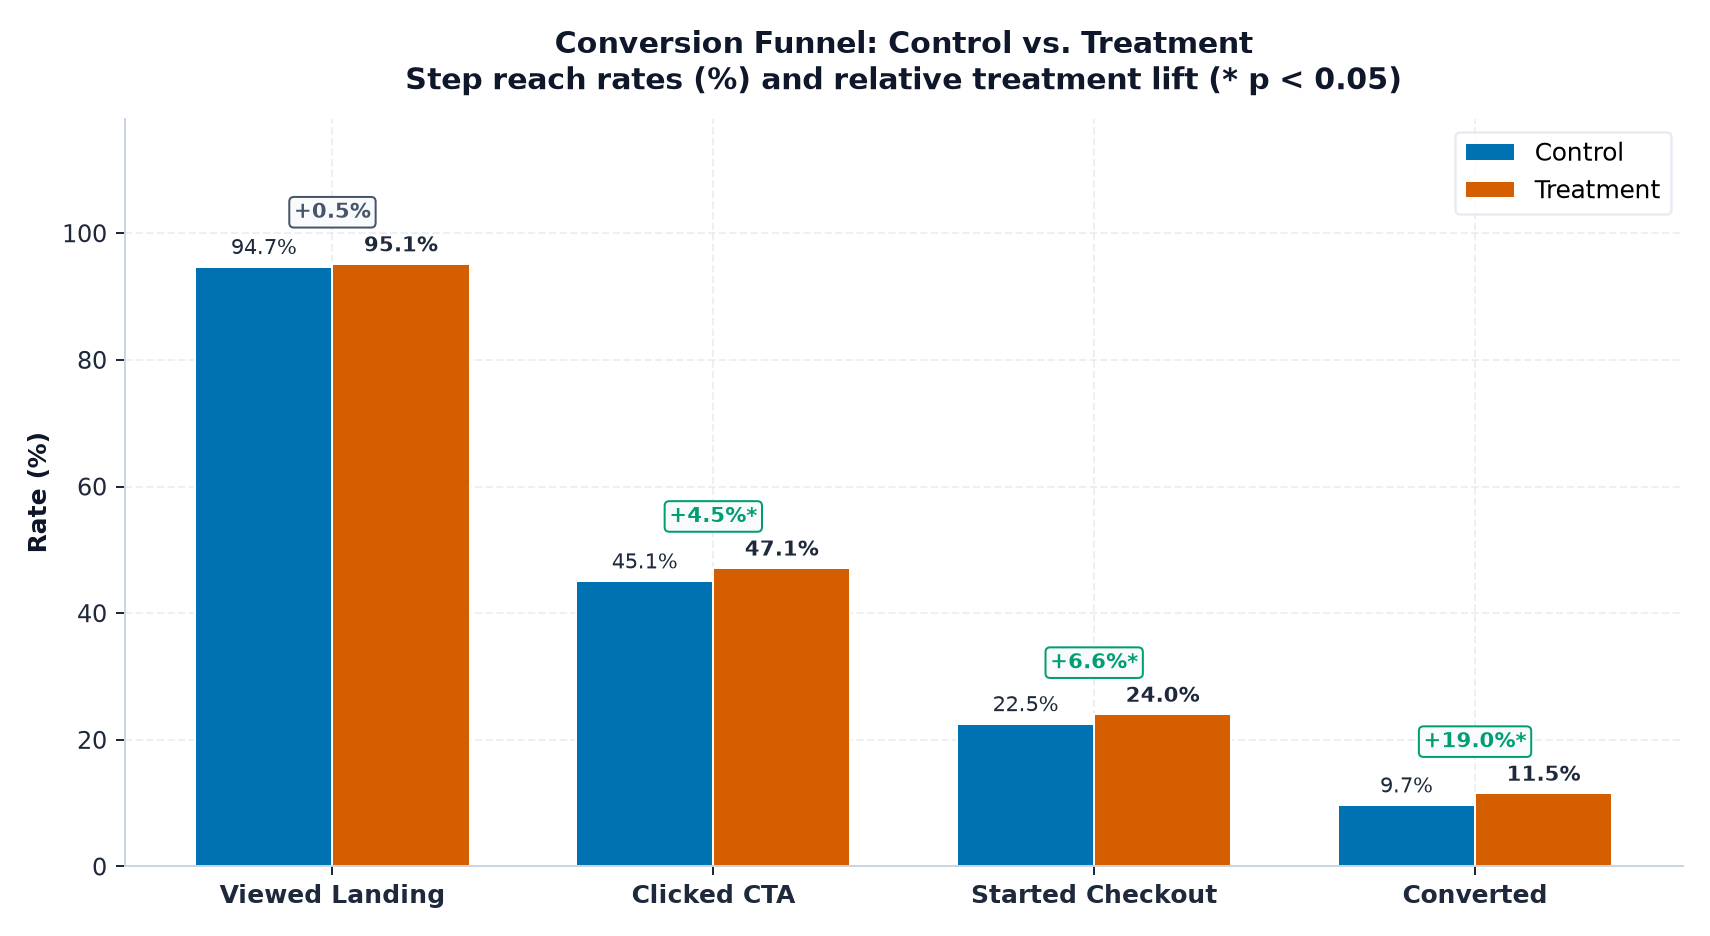

--- frequentist_ci_segments ---


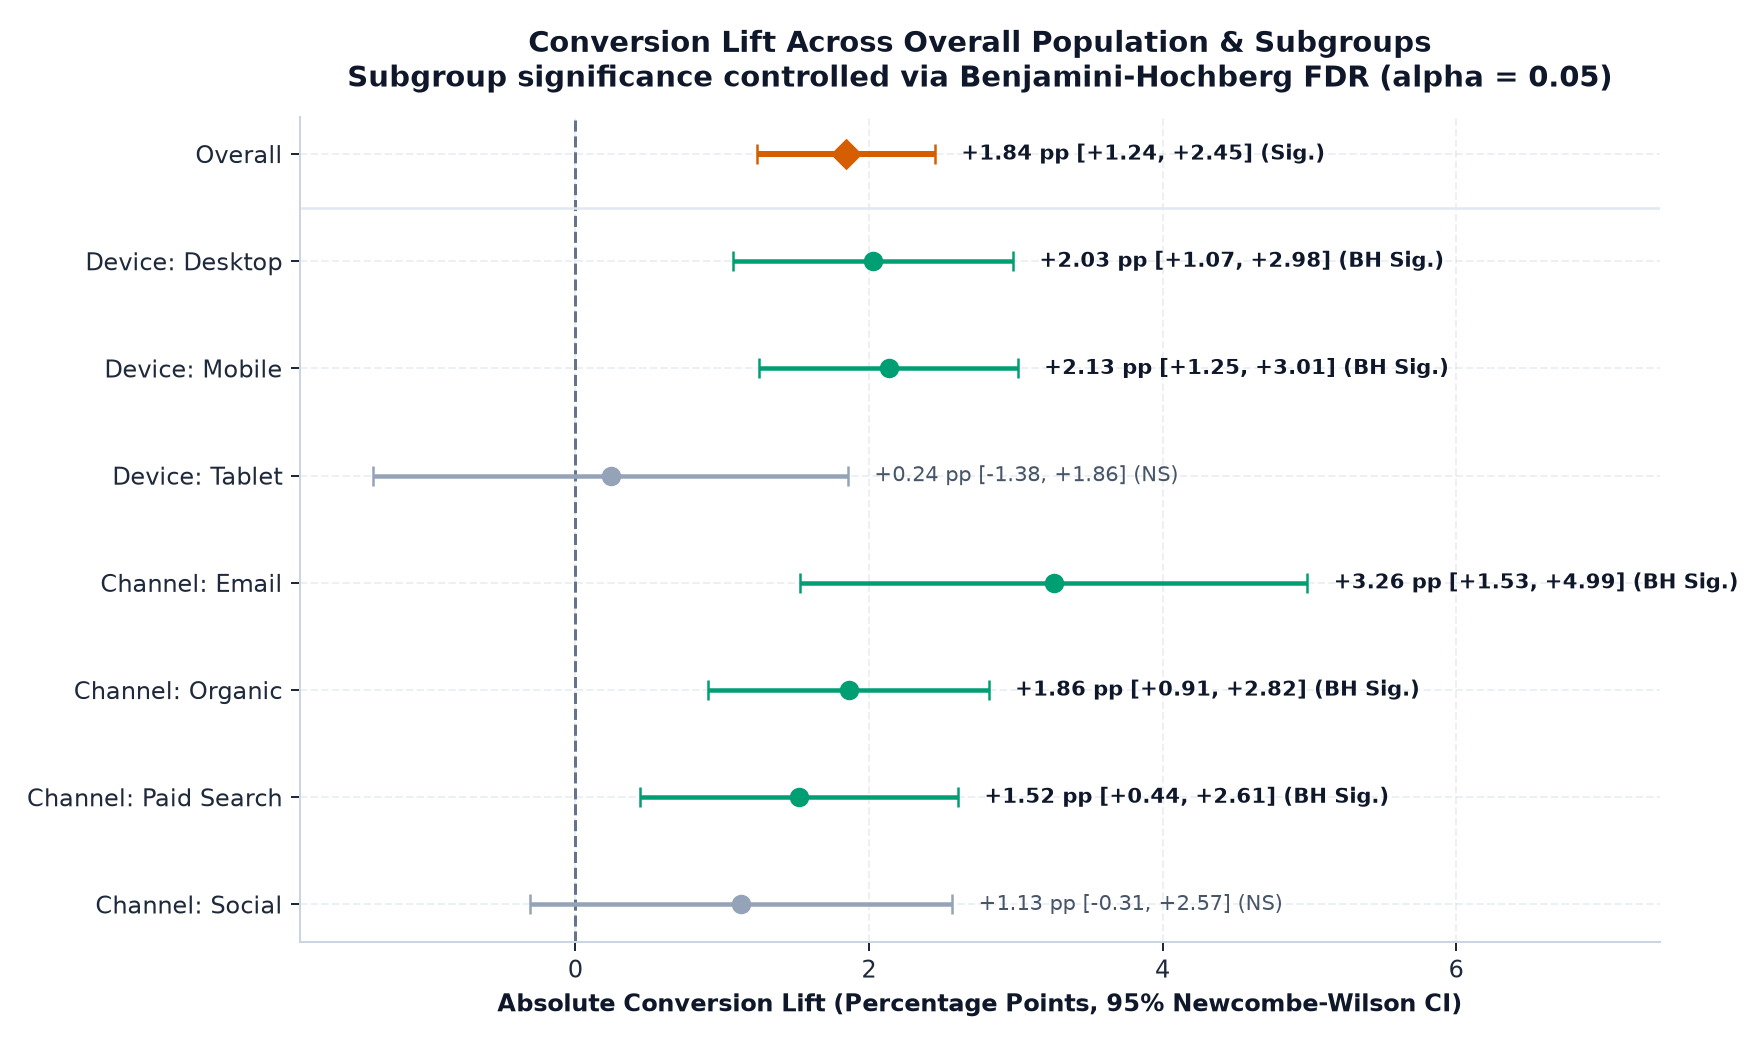

--- bayesian_posteriors ---


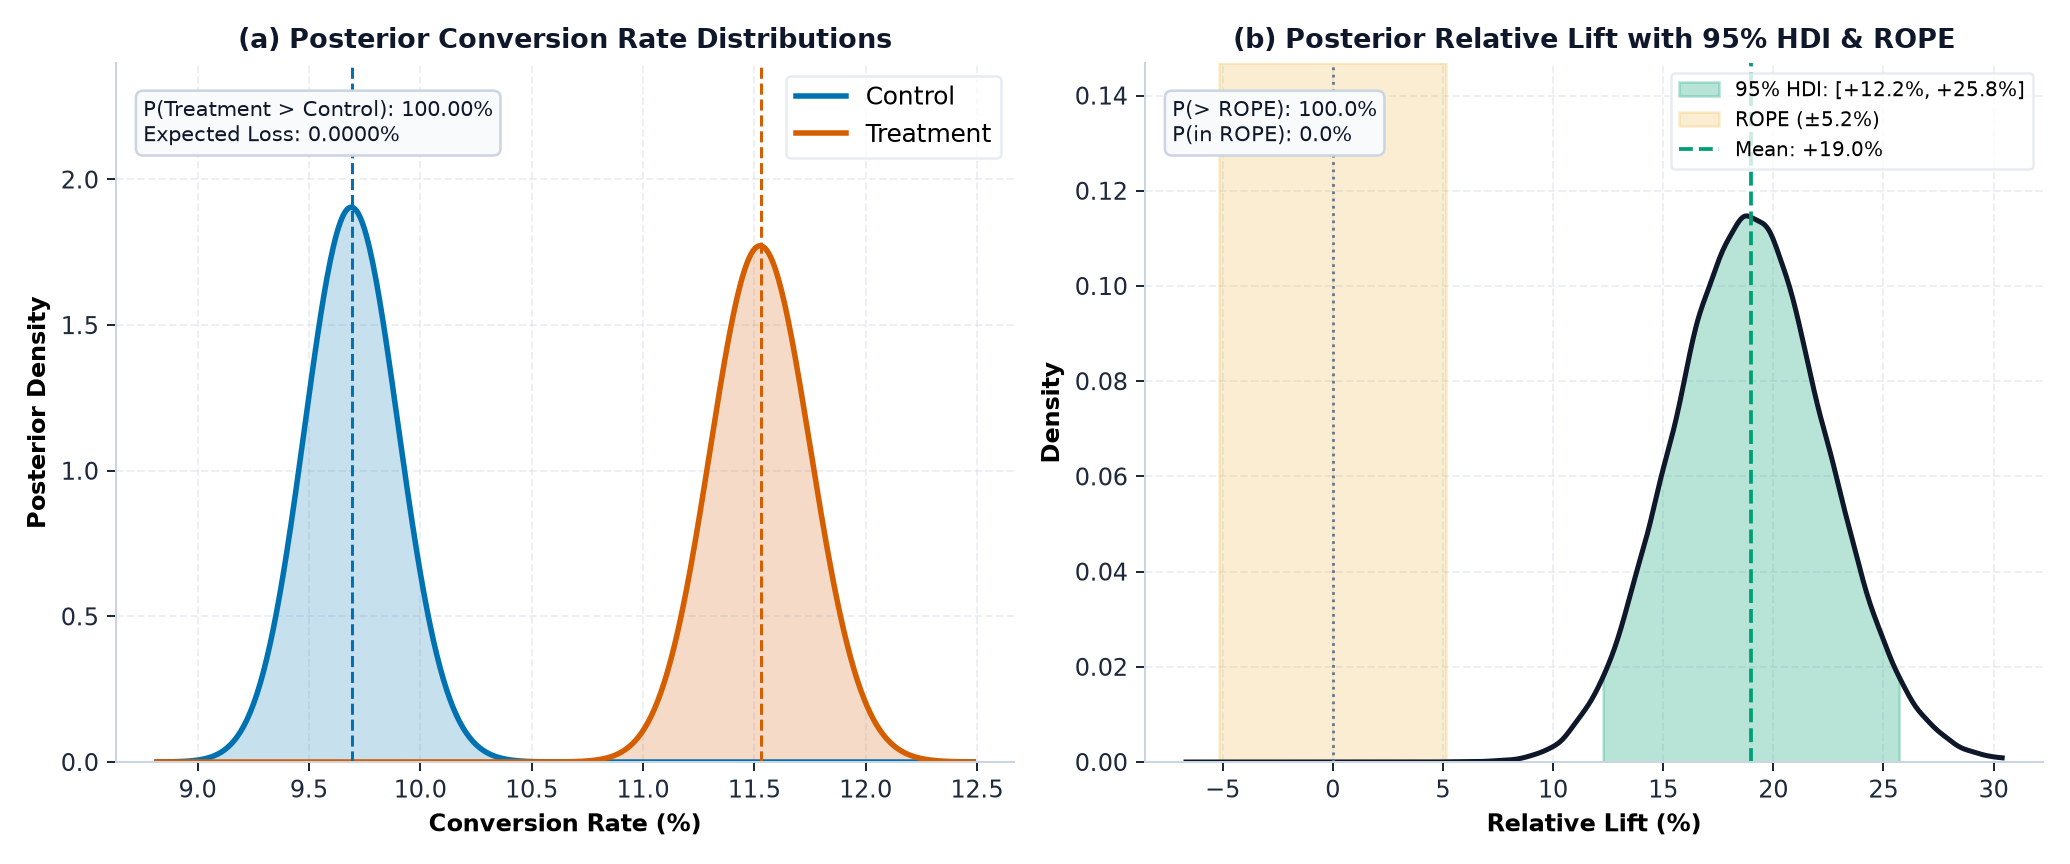

--- power_curve ---


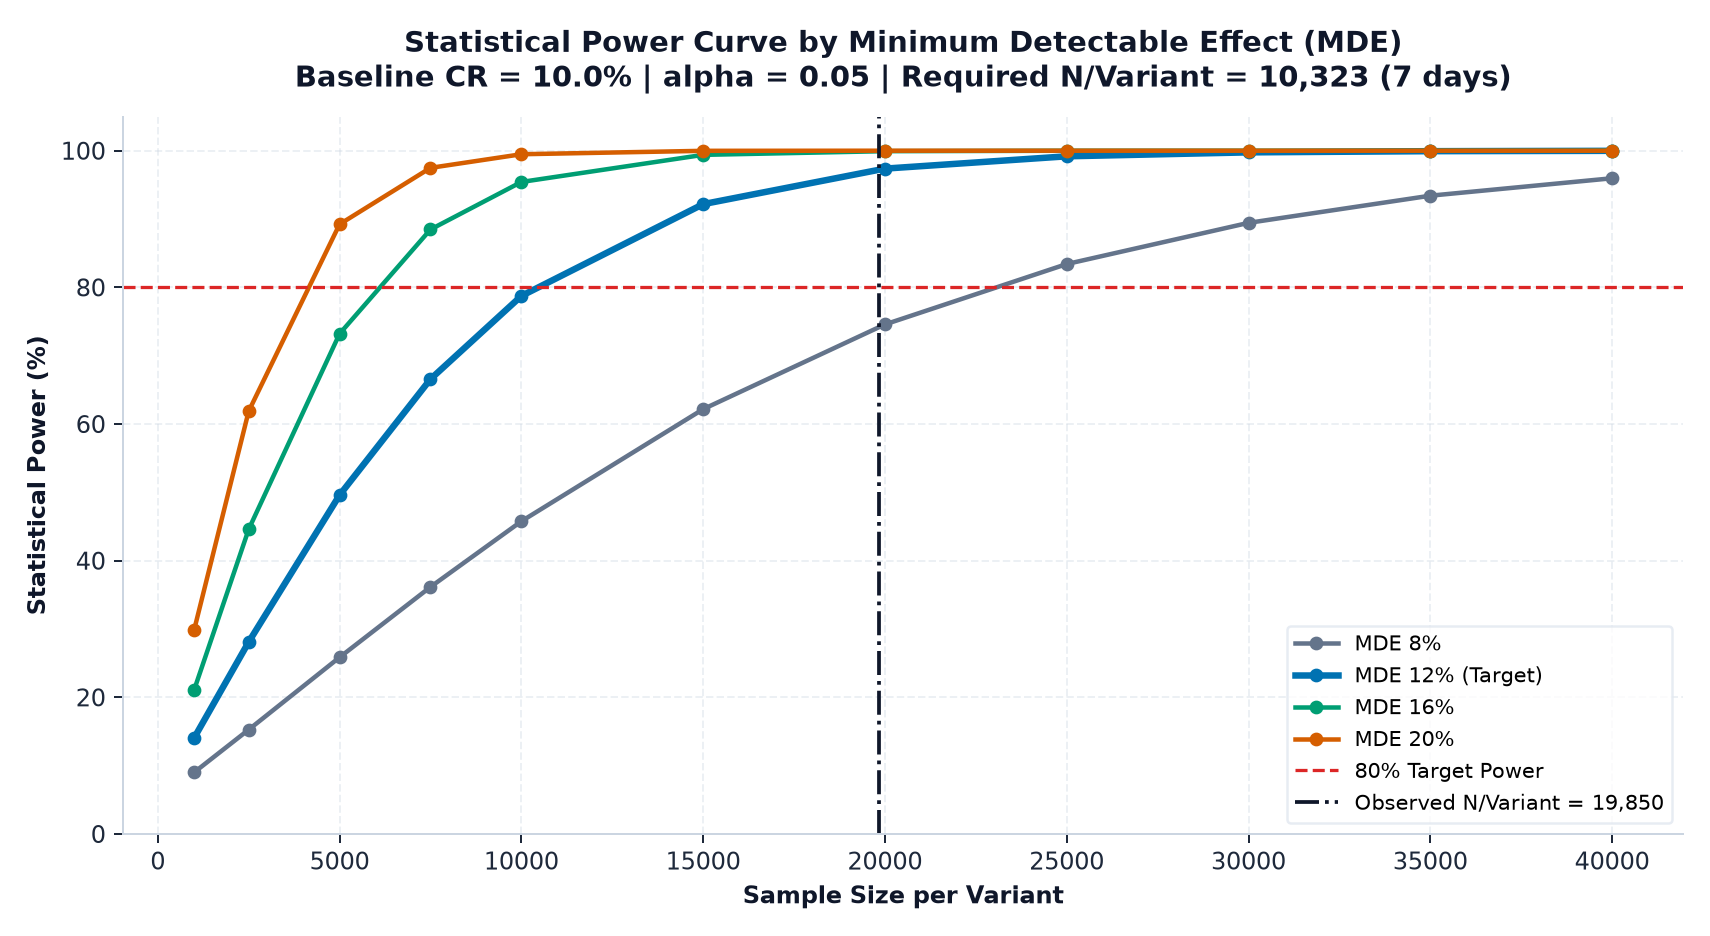

In [7]:
report = build_analysis_report(
    config=config,
    data_quality=quality,
    power_analysis=power_res,
    srm=srm,
    frequentist=freq,
    bayesian=bayes,
    locale='en',
)
fig_paths = generate_all_figures(
    frequentist=freq,
    bayesian=bayes,
    power=power_res,
    output_dir=ROOT / 'reports' / 'figures',
    locale='en',
    seed=config.seed,
)
print(f'Decision: {report.decision}')
print(report.recommendation_reason)
for name, path in fig_paths.items():
    print(f'--- {name} ---')
    ipy_display(Image(filename=str(path), width=760))